In [1]:
]activate ../../../../

  Activating project at `~/UCLOneDrive/SpatialStructureInMicrobialCommunities/SSMCCode`

In [2]:
using Revise
includet("./base.jl")

In [3]:
includet("../../../../scripts/figures_util.jl")

In [4]:
using GLMakie
using CairoMakie
CairoMakie.activate!()

# Produce analyzed dataframes for paper plots

In [6]:
add_extras_and_save("./main", "analyzed_df.jld2")

count(isnothing, df.early_time_modes) = 0

Progress: 100%|█████████████████████████████████████████| Time: 0:00:04WARNING: both Threads and SSMCMain export "Atomic"; uses of it in module ModifiedMiCRM must be qualified

# Get the data (full df here is ~1.5GB)

In [78]:
md = load("./setup.jld2", "metadata");
df = collect_pde_runs("./main");
show(names(df))
nrow(df)

["pde_df_row", "p_i", "p", "rep", "L", "sN", "T", "peak_k", "peak_h", "retcode", "final_state", "final_T", "maxresid", "num_saved", "realtime", "saved_ts", "saved_us", "settings", "mmp", "mmicrm_params", "Ds", "hss", "u0"]

72

# Early time length scales from FFT

In [79]:
using SSMCMain.ModifiedMiCRM.FFTAnalysis
using FFTW

In [80]:
df.early_time_modes = map(eachrow(df)) do r
    first_strong_mode(map(r.saved_us) do u @view u[1,:] end, r.L)
end;
count(isnothing, df.early_time_modes)

0

In [81]:
df.linstab_l = 2pi ./ df.peak_k;
df.et_l = map(df.early_time_modes) do etm etm.lengthscale end;

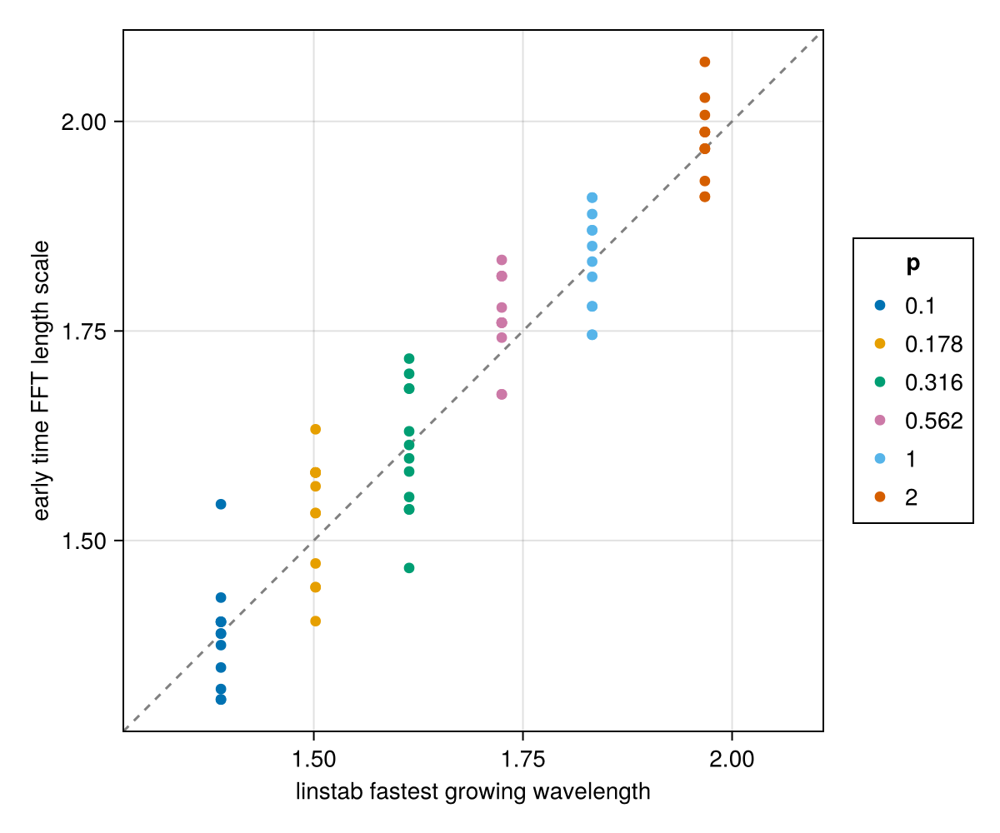

In [82]:
let
    lo, hi = extrema([df.linstab_l; df.et_l])
    pad = 0.05 * (hi - lo)
    fig = Figure(size=(600, 500))
    ax = Axis(fig[1, 1]; aspect=DataAspect(),
        xlabel="linstab fastest growing wavelength", ylabel="early time FFT length scale")
    ablines!(ax, 0, 1; color=:gray, linestyle=:dash)
    for p in sort(unique(df.p))
        sel = df.p .== p
        scatter!(ax, df.linstab_l[sel], df.et_l[sel]; label=@sprintf("%.3g", p))
    end
    limits!(ax, lo - pad, hi + pad, lo - pad, hi + pad)
    Legend(fig[1, 2], ax, "p")
    fig
end

# FFT testing

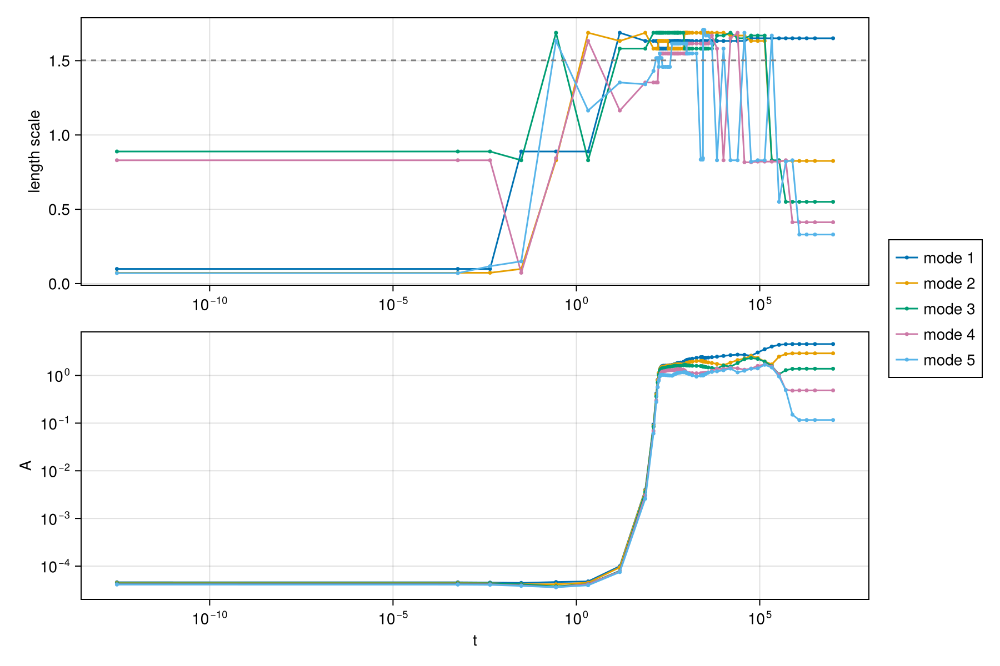

In [38]:
r = df[12*1+1,:]
num_modes = 5

using FFTW

# num_modes strongest modes of N at each saved time, strongest first
freqs = rfftfreq(r.sN, r.sN / r.L)[2:end]
dom = map(r.saved_us[2:end]) do u # t=0 can't go on a log axis
    F = rfft(u[1, :])[2:end] # skip the mean
    is = partialsortperm(abs.(F), 1:num_modes; rev=true)
    (; A=2 .* abs.(F[is]) ./ r.sN, ell=1 ./ freqs[is])
end
ts = r.saved_ts[2:end]

fig = Figure(size=(900, 600))
ax1 = Axis(fig[1, 1]; xscale=log10, ylabel="length scale")
ax2 = Axis(fig[2, 1]; xscale=log10, yscale=log10, xlabel="t", ylabel="A")
linkxaxes!(ax1, ax2)
for k in 1:num_modes
    scatterlines!(ax1, ts, [d.ell[k] for d in dom]; markersize=5, label="mode $k")
    scatterlines!(ax2, ts, [d.A[k] for d in dom]; markersize=5)
end
hlines!(ax1, 2pi / r.peak_k; color=:gray, linestyle=:dash) # linstab fastest growing wavelength
Legend(fig[1:2, 2], ax1)
fig

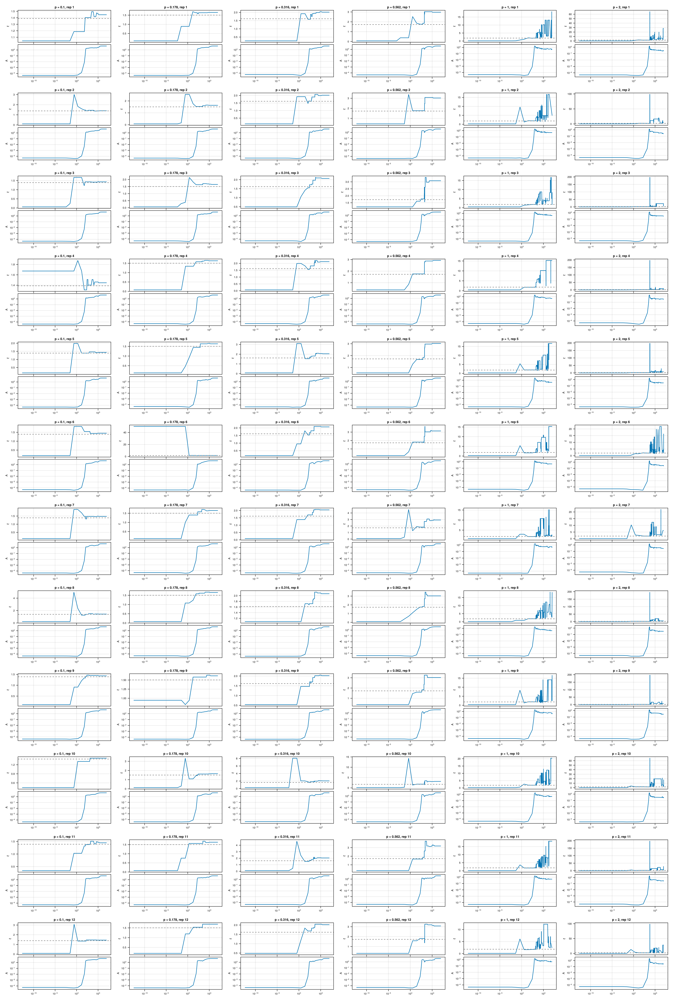

In [39]:
let
    fig = Figure(size=(350 * maximum(df.p_i), 260 * maximum(df.rep)))
    for r in eachrow(df)
        # strongest mode of N at each saved time
        freqs = rfftfreq(r.sN, r.sN / r.L)[2:end]
        dom = map(r.saved_us[2:end]) do u # t=0 can't go on a log axis
            F = rfft(u[1, :])[2:end] # skip the mean
            Fmax, i = findmax(abs.(F))
            (; A=2 * Fmax / r.sN, ell=1 / freqs[i])
        end
        ts = r.saved_ts[2:end]

        gl = GridLayout(fig[r.rep, r.p_i])
        ax1 = Axis(gl[1, 1]; xscale=log10, ylabel="ℓ",
            title=@sprintf("p = %.3g, rep %d", r.p, r.rep), titlesize=10,
            xticklabelsvisible=false, yticklabelsize=8, ylabelsize=9)
        ax2 = Axis(gl[2, 1]; xscale=log10, yscale=log10, ylabel="A",
            xticklabelsize=8, yticklabelsize=8, ylabelsize=9)
        linkxaxes!(ax1, ax2)
        rowgap!(gl, 2)
        lines!(ax1, ts, [d.ell for d in dom])
        hlines!(ax1, 2pi / r.peak_k; color=:gray, linestyle=:dash) # linstab fastest growing wavelength
        lines!(ax2, ts, [d.A for d in dom])
    end
    Makie.save("fft_dominant_mode.pdf", fig)
    fig
end

# Peak finding testing

In [111]:
r = df[end,:]

@show first_strong_mode(map(r.saved_us) do u @view u[1,:] end, r.L)

dx = r.L / r.sN
xs = ((1:r.sN) .- 0.5) .* dx
ex(e) = (e - 0.5) * dx # fractional gridpoint index to x
maxN = maximum(u -> maximum(view(u, 1, :)), r.saved_us)
maxprom = maximum(u -> -(reverse(extrema(view(u, 1, :)))...), r.saved_us)

fig = Figure(size=(1200, 750))
# min_* sliders at 0 mean no filter
sg = SliderGrid(fig[2, 1],
    (label="time index", range=eachindex(r.saved_ts), startvalue=1,
        format=i -> @sprintf("%d (t = %.3g)", i, r.saved_ts[i])),
    (label="w", range=1:50, startvalue=1),
    (label="min_prom", range=range(0, maxprom, 501), startvalue=0),
    (label="min_width (gridpoints)", range=range(0, r.sN / 4, 501), startvalue=0),
    (label="relheight", range=0.05:0.05:1.0, startvalue=0.5),
    (label="min_height", range=range(0, maxN, 501), startvalue=0),
)
ti, w, min_prom, min_width, relheight, min_height = [s.value for s in sg.sliders]
nofilter(v) = iszero(v) ? nothing : v

N = lift(i -> r.saved_us[i][1, :], ti)
pks = lift(N, w, min_prom, min_width, relheight, min_height) do N, w, mp, mw, rh, mh
    p = find_peaks_periodic(N; w, min_prom=nofilter(mp), min_width=nofilter(mw),
        relheight=rh, min_height=nofilter(mh))
    (; p..., N, relheight=rh)
end

# width lines and the shaded area above them, split where a peak wraps
overlay = lift(pks) do p
    segs = Pair{Point2f,Point2f}[]
    lo, hi = fill(NaN, r.sN), fill(NaN, r.sN)
    for (k, (l, rr)) in enumerate(p.edges)
        y = p.heights[k] - p.relheight * p.proms[k]
        if rr <= r.sN + 0.5
            push!(segs, Point2f(ex(l), y) => Point2f(ex(rr), y))
        else
            push!(segs, Point2f(ex(l), y) => Point2f(r.L, y), Point2f(0, y) => Point2f(ex(rr - r.sN), y))
        end
        for j in mod1.(ceil(Int, l):floor(Int, rr), r.sN)
            lo[j], hi[j] = y, p.N[j]
        end
    end
    (; segs, lo, hi)
end

title = lift((i, p) -> @sprintf("t = %.3g, %d peaks", r.saved_ts[i], length(p.indices)), ti, pks)
ax = Axis(fig[1, 1]; xlabel="x", ylabel="N", title)
band!(ax, xs, lift(o -> o.lo, overlay), lift(o -> o.hi, overlay); color=(:orange, 0.4))
lines!(ax, xs, N)
linesegments!(ax, lift(o -> o.segs, overlay); color=:black)
scatter!(ax, lift(p -> Point2f.(xs[p.indices], p.heights), pks); color=:red)
limits!(ax, 0, r.L, 0, 1.05maxN) # fixed, covers every saved time

display(GLMakie.Screen(), fig)

first_strong_mode(map(r.saved_us) do u
        #= In[111]:3 =#
        #= In[111]:3 =# @view u[1, :]
    end, r.L) = (ti = 14, A = 1.1267342140583219, lengthscale = 2.0076064342809343)

GLMakie.Screen(...)

# Getting peak counts after early times

In [112]:
df.peaks = @showprogress map(eachrow(df)) do r
    map(r.saved_us) do u
        find_peaks_periodic(@view u[1,:];
            min_prom=0.1,
        )
    end
end;

Progress: 100%|█████████████████████████████████████████| Time: 0:00:10

In [113]:
df.num_peaks = map(eachrow(df)) do r
    map(r.peaks) do pks length(pks.indices) end
end;

In [114]:
df.et_tis = map(df.early_time_modes) do x x.ti end;

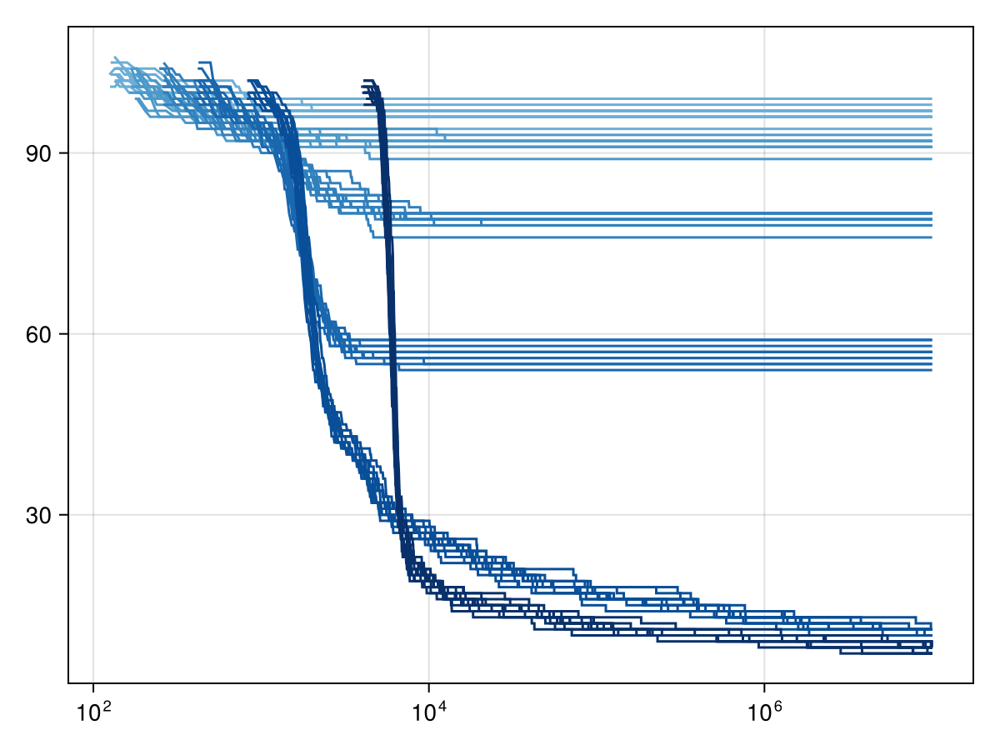

In [117]:
fig = Figure()
ax = Axis(fig[1,1];
    xscale=log10,
)

for r in eachrow(df)
    ti = r.early_time_modes.ti
    ts = r.saved_ts[ti:end]
    ns = r.num_peaks[ti:end]
    lines!(ax, ts, ns;
        color=PaperColors.p_color1(r.p)
    )
end

fig

# Old peak finding based methods

## Setting early times based on stats

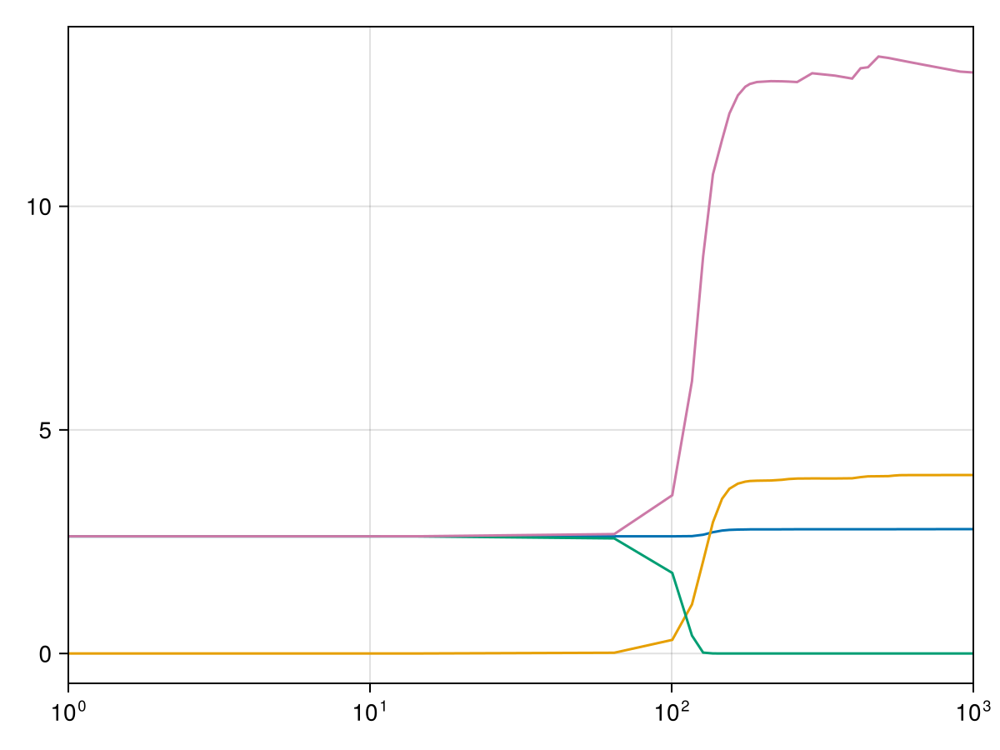

In [72]:
r = df[1,:];

fig = Figure()
ax = Axis(fig[1,1];
    xscale=log10,
)

means = map(r.saved_us) do u mean(@view u[1,:]) end
stds = map(r.saved_us) do u std(@view u[1,:]) end
maxs = map(r.saved_us) do u maximum(@view u[1,:]) end
mins = map(r.saved_us) do u minimum(@view u[1,:]) end
lines!(ax, r.saved_ts, means)
lines!(ax, r.saved_ts, stds)
lines!(ax, r.saved_ts, mins)
lines!(ax, r.saved_ts, maxs)

fig

In [81]:
# finds for each PDE run at which time index the spread between max and min becomes bigger than the mean
min_tis = map(eachrow(df)) do r
    tii = nothing
    for ti in 1:length(r.saved_us)
        u = @view r.saved_us[ti][1,:]
        ee = extrema(u)
        if (ee[2] - ee[1]) > mean(u)
            tii = ti
            break
        end
    end
    tii
end;

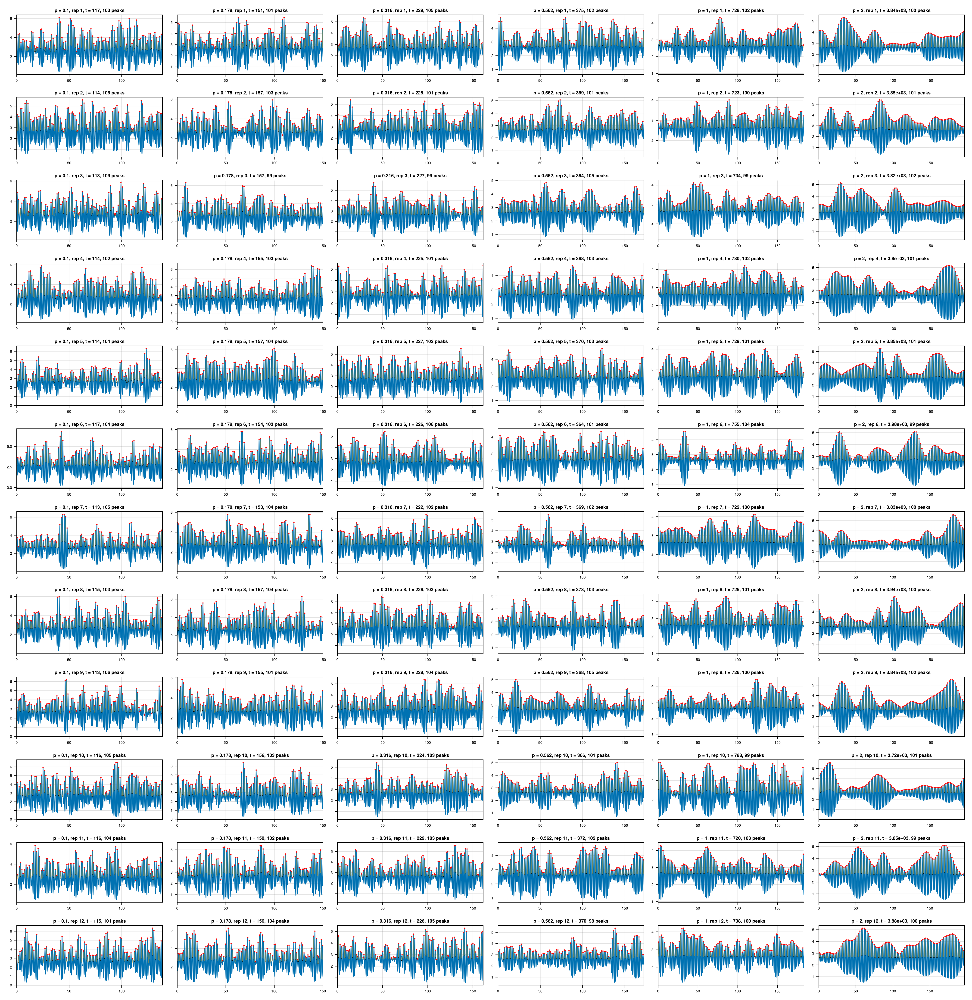

In [85]:
# peak finding parameters, nothing means no filter
pk_w = 1
pk_min_prom = nothing
pk_min_width = nothing
pk_relheight = 0.5
pk_min_height = nothing

let
    fig = Figure(size=(350 * maximum(df.p_i), 180 * maximum(df.rep)))
    for (r, ti) in zip(eachrow(df), min_tis)
        dx = r.L / r.sN
        xs = ((1:r.sN) .- 0.5) .* dx
        ex(e) = (e - 0.5) * dx
        N = r.saved_us[ti][1, :]
        p = find_peaks_periodic(N; w=pk_w, min_prom=pk_min_prom, min_width=pk_min_width,
            relheight=pk_relheight, min_height=pk_min_height)

        ax = Axis(fig[r.rep, r.p_i];
            title=@sprintf("p = %.3g, rep %d, t = %.3g, %d peaks", r.p, r.rep, r.saved_ts[ti], length(p.indices)),
            titlesize=10, xticklabelsize=8, yticklabelsize=8)
        lines!(ax, xs, N)
        if !isempty(p.indices)
            # width lines and the shaded area above them, split where a peak wraps
            segs = Pair{Point2f,Point2f}[]
            lo, hi = fill(NaN, r.sN), fill(NaN, r.sN)
            for (k, (l, rr)) in enumerate(p.edges)
                y = p.heights[k] - pk_relheight * p.proms[k]
                if rr <= r.sN + 0.5
                    push!(segs, Point2f(ex(l), y) => Point2f(ex(rr), y))
                else
                    push!(segs, Point2f(ex(l), y) => Point2f(r.L, y), Point2f(0, y) => Point2f(ex(rr - r.sN), y))
                end
                for j in mod1.(ceil(Int, l):floor(Int, rr), r.sN)
                    lo[j], hi[j] = y, N[j]
                end
            end
            band!(ax, xs, lo, hi; color=(:orange, 0.4))
            linesegments!(ax, segs; color=:black, linewidth=0.5)
            scatter!(ax, xs[p.indices], p.heights; color=:red, markersize=4)
        end
        xlims!(ax, 0, r.L)
    end
    Makie.save("peaks_at_min_tis.pdf", fig)
    fig
end

## Interactive peak finding demo

In [77]:
r = df[1,:]

dx = r.L / r.sN
xs = ((1:r.sN) .- 0.5) .* dx
ex(e) = (e - 0.5) * dx # fractional gridpoint index to x
maxN = maximum(u -> maximum(view(u, 1, :)), r.saved_us)
maxprom = maximum(u -> -(reverse(extrema(view(u, 1, :)))...), r.saved_us)

fig = Figure(size=(1200, 750))
# min_* sliders at 0 mean no filter
sg = SliderGrid(fig[2, 1],
    (label="time index", range=eachindex(r.saved_ts), startvalue=1,
        format=i -> @sprintf("%d (t = %.3g)", i, r.saved_ts[i])),
    (label="w", range=1:50, startvalue=1),
    (label="min_prom", range=range(0, maxprom, 501), startvalue=0),
    (label="min_width (gridpoints)", range=range(0, r.sN / 4, 501), startvalue=0),
    (label="relheight", range=0.05:0.05:1.0, startvalue=0.5),
    (label="min_height", range=range(0, maxN, 501), startvalue=0),
)
ti, w, min_prom, min_width, relheight, min_height = [s.value for s in sg.sliders]
nofilter(v) = iszero(v) ? nothing : v

N = lift(i -> r.saved_us[i][1, :], ti)
pks = lift(N, w, min_prom, min_width, relheight, min_height) do N, w, mp, mw, rh, mh
    p = find_peaks_periodic(N; w, min_prom=nofilter(mp), min_width=nofilter(mw),
        relheight=rh, min_height=nofilter(mh))
    (; p..., N, relheight=rh)
end

# width lines and the shaded area above them, split where a peak wraps
overlay = lift(pks) do p
    segs = Pair{Point2f,Point2f}[]
    lo, hi = fill(NaN, r.sN), fill(NaN, r.sN)
    for (k, (l, rr)) in enumerate(p.edges)
        y = p.heights[k] - p.relheight * p.proms[k]
        if rr <= r.sN + 0.5
            push!(segs, Point2f(ex(l), y) => Point2f(ex(rr), y))
        else
            push!(segs, Point2f(ex(l), y) => Point2f(r.L, y), Point2f(0, y) => Point2f(ex(rr - r.sN), y))
        end
        for j in mod1.(ceil(Int, l):floor(Int, rr), r.sN)
            lo[j], hi[j] = y, p.N[j]
        end
    end
    (; segs, lo, hi)
end

title = lift((i, p) -> @sprintf("t = %.3g, %d peaks", r.saved_ts[i], length(p.indices)), ti, pks)
ax = Axis(fig[1, 1]; xlabel="x", ylabel="N", title)
band!(ax, xs, lift(o -> o.lo, overlay), lift(o -> o.hi, overlay); color=(:orange, 0.4))
lines!(ax, xs, N)
linesegments!(ax, lift(o -> o.segs, overlay); color=:black)
scatter!(ax, lift(p -> Point2f.(xs[p.indices], p.heights), pks); color=:red)
limits!(ax, 0, r.L, 0, 1.05maxN) # fixed, covers every saved time

display(GLMakie.Screen(), fig)

GLMakie.Screen(...)